# Endothelial-Cell Distance Analysis: Sample-Level Statistical Testing

> This notebook adds formal statistical testing on top of the existing per-dataset
distance-analysis notebooks (`distance_analysis__*.ipynb`). It is meant to run
**after** you already have `-edges.csv` / `-nodes.csv` files processed for each
dataset (i.e., after `data_processing__distance_computation_for_all_datasets`).

### Why this exists

The existing notebooks compute mean/median/min/max distance and coefficient of
variation by pooling **every cell** within a region/condition/tissue-subtype.
Because cells within the same sample (donor, section, biopsy) are spatially and
biologically correlated, treating each cell as an independent observation
massively inflates statistical power — with millions of cells, even a
biologically meaningless <1 µm difference in EC distance can look "significant."

**The fix used throughout this notebook:** collapse to one summary value
(median distance) per `Dataset` (i.e., per sample/section/biopsy) per cell
type *before* comparing groups. This is the same `Dataset` column already
present in every one of your edges dataframes.

### What's in this version

Every one of the 13 dataset notebooks in the collection (excluding
`pancreas-geomx-ufl`, dropped from the paper per reviewer feedback on small
donor count) has been wired up below using the **exact grouping/region logic
already in that dataset's own notebook** — no placeholders. Sample counts per
group were confirmed directly from each notebook's output before writing this,
summarized here:

| Dataset | Comparison | Groups (n samples) | Outcome |
|---|---|---|---|
| intestine-codex-stanford | Small vs. Large Intestine | 32 vs. 32 | Tested |
| intestine-codex-stanford | Across 8 regions | 8 groups, 8 each | Tested (Kruskal-Wallis) |
| bonemarrow-codex-chop | AML vs. NBM vs. NSM | 5 / 12 / 3 | Tested (NSM low-powered) |
| mouth-codex-czi | Across 5 regions | Buccal=2, Gingiva=2, Parotid=4, Submandibular=2, Tongue=3 | Mixed — some cell types descriptive-only |
| colon-xenium vs. colon-cycif | Cross-technology | 29 vs. 25 | Tested (confounded — see caveat) |
| lymphnode-codex-yale | Inter-donor (5 donors) | 1 each | Descriptive only |
| spleen-codex-ufl | Inter-donor (6 donors) | 1 each | Descriptive only |
| skin-celldive-ge | Inter-region (10 regions) | 1 each | Descriptive only |
| lung-codex-urmc | Healthy vs. Disease | 1 vs. 1 | Descriptive only |
| skin-confocal-sorgerlab | Melanoma in situ vs. Invasive margin | 1 vs. 1 | Descriptive only |
| tonsil vs. esophagus | Cross-tissue | 1 vs. 1 | Descriptive only |
| maternalfetalinterface-mibitof-stanford | — | 209 samples, but **no grouping variable exists** (single region) | Not applicable — see note in Section 5k |

### What this notebook produces

For every comparison, it:

1. Collapses cell-level distances to one median value per `Dataset` per cell type.
2. Runs a **Mann-Whitney U test** (2 groups) or **Kruskal-Wallis test** (>2 groups).
3. Computes an **effect size** — Cliff's delta (2-group) or epsilon-squared (Kruskal-Wallis).
4. Applies **Benjamini-Hochberg FDR correction** within each comparison's family of cell-type tests.
5. Flags any group with fewer than `MIN_SAMPLES_PER_GROUP` samples as
   **"descriptive only — not tested"** rather than silently running an invalid test.
6. Compiles everything into one master results table.

### A note on the >MIN_SAMPLES_PER_GROUP guard and single-sample groups

Several datasets above (lung, skin-confocal, tonsil/esophagus, and every
per-donor/per-region comparison in lymph node, spleen, and skin-celldive) have
group sizes of exactly 1. These are run through the pipeline anyway — not
because a test is expected to succeed, but so the **same code path** produces
the "descriptive only" flag automatically and consistently, rather than you
having to remember which datasets to skip.


## 1. Imports and shared setup

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

try:
    import scikit_posthocs as sp
    HAVE_POSTHOCS = True
except ImportError:
    HAVE_POSTHOCS = False
    print("scikit-posthocs not installed — pairwise post-hoc tests after "
          "Kruskal-Wallis will be skipped. Install with: "
          "pip install scikit-posthocs --break-system-packages")

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

import warnings
warnings.filterwarnings("ignore")

# Minimum number of samples (Dataset values) required per group before we will
# run a test at all. Below this, the comparison is reported as descriptive only.
MIN_SAMPLES_PER_GROUP = 3

# Where the master results table (CSV) will be written.

basepath = "/Users/yashjain/Coding/cns/hra-cell-distance-analysis/data"

RESULTS_OUTPUT_PATH = basepath + "/distance_analysis_statistical_results.csv"


## 2. Shared data-loading functions

Two loader variants are needed because the file-naming convention differs by
one dataset (`lung-codex-urmc` uses a 4-part dataset name before the anchor
level/type suffix; everything else uses a single-part name). Both are reused
unchanged from the individual notebooks.


In [2]:
def load_data(path, edges=False):
    if edges:
        column_names = ['cell_id', 'x1', 'y1', 'z1', 'x2', 'y2', 'z2']
        data = pd.read_csv(path, header=None, names=column_names)
    else:
        data = pd.read_csv(path)
    return data


def read_all_edge_datasets(basepath, data_filedir, output_edge_dir):
    """Standard loader: filename format is '<dataset>-<level>-<anchor>-edges.csv'.
    Used by every dataset except lung-codex-urmc.
    """
    all_nodes_files = []
    all_edges_files = []
    all_nodes_edges_files = []
    for file in os.listdir(os.path.join(basepath, output_edge_dir)):
        if file.endswith("-edges.csv"):
            file_path = os.path.join(basepath, output_edge_dir, file)
            dataset_name, anchor_cell_type_level, anchor_cell_type = (
                file.replace("-edges.csv", "").split('-')
            )
            edges_df = load_data(file_path, edges=False)
            edges_df['Dataset'] = dataset_name
            edges_df['Anchor Cell Type'] = anchor_cell_type
            edges_df['Anchor Cell Type Level'] = anchor_cell_type_level
            edges_df.rename(columns={"distance": "Distance"}, inplace=True)
            all_edges_files.append(edges_df)

            nodes_file_path = os.path.join(basepath, data_filedir, f"{dataset_name}-nodes.csv")
            nodes_df = load_data(nodes_file_path)
            nodes_df['Dataset'] = dataset_name
            all_nodes_files.append(nodes_df)

            nodes_df['cell_id'] = range(len(nodes_df))
            nodes_df.set_index('cell_id', inplace=True)
            edges_nodes_df = pd.merge(
                edges_df,
                nodes_df[['Level Three Cell Type', 'Level Two Cell Type', 'Level One Cell Type']],
                how='left', left_on='cell_id', right_index=True
            )
            all_nodes_edges_files.append(edges_nodes_df)

    merged_edges = pd.concat(all_edges_files, ignore_index=True)
    merged_nodes = pd.concat(all_nodes_files, ignore_index=True)
    merged_nodes_for_all_edges = pd.concat(all_nodes_edges_files, ignore_index=True)

    return merged_nodes, merged_edges, merged_nodes_for_all_edges


def read_all_edge_datasets_lung(basepath, data_filedir, output_edge_dir):
    """Lung-specific loader: filename format is
    '<d1>-<d2>-<d3>-<d4>-<level>-<anchor>-edges.csv', i.e. the dataset name
    itself contains hyphens (e.g. 'D265-LLL-7A7-12'), so the first four
    hyphen-separated parts are joined back into the dataset name.
    """
    all_nodes_files = []
    all_edges_files = []
    all_nodes_edges_files = []
    for file in os.listdir(os.path.join(basepath, output_edge_dir)):
        if file.endswith("-edges.csv"):
            file_path = os.path.join(basepath, output_edge_dir, file)
            d1, d2, d3, d4, anchor_cell_type_level, anchor_cell_type = (
                file.replace("-edges.csv", "").split('-')
            )
            dataset_name = f'{d1}-{d2}-{d3}-{d4}'
            edges_df = load_data(file_path, edges=False)
            edges_df['Dataset'] = dataset_name
            edges_df['Anchor Cell Type'] = anchor_cell_type
            edges_df['Anchor Cell Type Level'] = anchor_cell_type_level
            edges_df.rename(columns={"distance": "Distance"}, inplace=True)
            all_edges_files.append(edges_df)

            nodes_file_path = os.path.join(basepath, data_filedir, f"{dataset_name}-nodes.csv")
            nodes_df = load_data(nodes_file_path)
            nodes_df['Dataset'] = dataset_name
            all_nodes_files.append(nodes_df)

            nodes_df['cell_id'] = range(len(nodes_df))
            nodes_df.set_index('cell_id', inplace=True)
            edges_nodes_df = pd.merge(
                edges_df,
                nodes_df[['Level Three Cell Type', 'Level Two Cell Type', 'Level One Cell Type']],
                how='left', left_on='cell_id', right_index=True
            )
            all_nodes_edges_files.append(edges_nodes_df)

    merged_edges = pd.concat(all_edges_files, ignore_index=True)
    merged_nodes = pd.concat(all_nodes_files, ignore_index=True)
    merged_nodes_for_all_edges = pd.concat(all_nodes_edges_files, ignore_index=True)

    return merged_nodes, merged_edges, merged_nodes_for_all_edges


## 3. Statistical testing functions

In [3]:
def sample_level_table(df_edges, cell_type_level, group_col):
    """Collapse cell-level edges to one median Distance per Dataset per cell type."""
    return (
        df_edges
        .groupby(['Dataset', cell_type_level, group_col])['Distance']
        .median()
        .reset_index()
        .rename(columns={'Distance': 'median_distance'})
    )


def cliffs_delta(a, b):
    """Rank-based effect size. -1 to 1; 0.11 small, 0.28 medium, 0.43 large."""
    a = np.asarray(a)
    b = np.asarray(b)
    n_a, n_b = len(a), len(b)
    greater = sum(x > y for x in a for y in b)
    less = sum(x < y for x in a for y in b)
    return (greater - less) / (n_a * n_b)


def epsilon_squared(h_stat, n):
    """Effect size for Kruskal-Wallis. 0.01 small, 0.06 medium, 0.14 large."""
    return h_stat / (n - 1) if n > 1 else np.nan


def test_one_cell_type(sample_df, cell_type_level, group_col, cell_type, groups,
                        min_n=MIN_SAMPLES_PER_GROUP):
    sub = sample_df[sample_df[cell_type_level] == cell_type]
    group_values = {g: sub[sub[group_col] == g]['median_distance'].values for g in groups}
    group_sizes = {g: len(v) for g, v in group_values.items()}

    underpowered = any(n < min_n for n in group_sizes.values())

    result = {
        'Cell Type': cell_type,
        'Groups Compared': ' vs '.join(str(g) for g in groups),
        **{f'n_{g}': group_sizes[g] for g in groups},
    }

    if underpowered:
        result.update({
            'Test': 'None (insufficient samples)',
            'Statistic': np.nan,
            'p_value': np.nan,
            'Effect Size': np.nan,
            'Effect Size Type': None,
            'Status': 'Descriptive only — not tested',
        })
        return result

    if len(groups) == 2:
        a, b = group_values[groups[0]], group_values[groups[1]]
        stat, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        delta = cliffs_delta(a, b)
        result.update({
            'Test': 'Mann-Whitney U',
            'Statistic': stat,
            'p_value': p,
            'Effect Size': delta,
            'Effect Size Type': "Cliff's delta",
            'Status': 'Tested',
        })
    else:
        arrays = [group_values[g] for g in groups]
        stat, p = stats.kruskal(*arrays)
        n_total = sum(group_sizes.values())
        eps2 = epsilon_squared(stat, n_total)
        result.update({
            'Test': 'Kruskal-Wallis',
            'Statistic': stat,
            'p_value': p,
            'Effect Size': eps2,
            'Effect Size Type': 'epsilon-squared',
            'Status': 'Tested',
        })

    return result


def run_comparison(df_edges, cell_type_level, group_col, groups, study_name,
                    comparison_name, anchor_cell_type=None, anchor_cell_type_level=None,
                    min_n=MIN_SAMPLES_PER_GROUP):
    df = df_edges.copy()
    if anchor_cell_type is not None:
        df = df[df['Anchor Cell Type'] == anchor_cell_type]
    if anchor_cell_type_level is not None:
        df = df[df['Anchor Cell Type Level'] == anchor_cell_type_level]
    df = df[df[group_col].isin(groups)]

    sample_df = sample_level_table(df, cell_type_level, group_col)

    rows = []
    for ct in sorted(sample_df[cell_type_level].dropna().unique()):
        row = test_one_cell_type(sample_df, cell_type_level, group_col, ct, groups, min_n=min_n)
        rows.append(row)

    results = pd.DataFrame(rows)
    results.insert(0, 'Study', study_name)
    results.insert(1, 'Comparison', comparison_name)
    results.insert(2, 'Cell Type Level', cell_type_level)

    tested_mask = results['Status'] == 'Tested'
    if tested_mask.sum() > 0:
        results.loc[tested_mask, 'p_adj (FDR)'] = multipletests(
            results.loc[tested_mask, 'p_value'], method='fdr_bh'
        )[1]
    else:
        results['p_adj (FDR)'] = np.nan

    return results


def run_posthoc_dunn(df_edges, cell_type_level, group_col, cell_type, groups,
                      anchor_cell_type=None, anchor_cell_type_level=None):
    """Pairwise Dunn's test (BH-corrected) after a significant Kruskal-Wallis.
    Requires scikit-posthocs.
    """
    if not HAVE_POSTHOCS:
        print("scikit-posthocs not available — skipping post-hoc test.")
        return None

    df = df_edges.copy()
    if anchor_cell_type is not None:
        df = df[df['Anchor Cell Type'] == anchor_cell_type]
    if anchor_cell_type_level is not None:
        df = df[df['Anchor Cell Type Level'] == anchor_cell_type_level]
    df = df[df[group_col].isin(groups)]

    sample_df = sample_level_table(df, cell_type_level, group_col)
    sub = sample_df[sample_df[cell_type_level] == cell_type]

    return sp.posthoc_dunn(sub, val_col='median_distance', group_col=group_col, p_adjust='fdr_bh')


## 4. Master results collector

In [4]:
all_results = []

def register_results(results_df):
    all_results.append(results_df)
    n_tested = (results_df['Status'] == 'Tested').sum()
    n_skipped = (results_df['Status'] != 'Tested').sum()
    print(f"[{results_df['Study'].iloc[0]} | {results_df['Comparison'].iloc[0]}] "
          f"{n_tested} cell types tested, {n_skipped} descriptive-only "
          f"(insufficient samples).")


## 5. Dataset-by-dataset comparisons

### 5a. intestine-codex-stanford — Small vs. Large Intestine

In [ ]:
dataset_dir = "intestine-codex-stanford"
data_filedir = os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir)
output_edge_dir = os.path.join("data-processed-edges", dataset_dir)

_, _, df_intestine_edges = read_all_edge_datasets(basepath, data_filedir, output_edge_dir)

si = ['Duodenum', 'Ileum', 'Mid', 'ProximalJejunum', 'Midjejunum', 'Proximaljejunum']
li = ['Ascending', 'Descending', 'Transverse', 'Left', 'Right', 'Sigmoid', 'Trans']

df_intestine_edges['Donor'] = df_intestine_edges['Dataset'].str.split('_').str[0]
df_intestine_edges['Tissue Subtype'] = df_intestine_edges['Dataset'].str.split('_').str[1].apply(
    lambda x: 'Small Intestine' if x in si else ('Large Intestine' if x in li else 'Unknown')
)

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell'),
                       ('Level Three Cell Type', 'endothelial cell')]:
    res = run_comparison(
        df_intestine_edges, level, 'Tissue Subtype',
        ['Small Intestine', 'Large Intestine'],
        'intestine-codex-stanford', 'Small vs. Large Intestine',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)

[intestine-codex-stanford | Small vs. Large Intestine] 4 cell types tested, 0 descriptive-only (insufficient samples).
[intestine-codex-stanford | Small vs. Large Intestine] 16 cell types tested, 0 descriptive-only (insufficient samples).
[intestine-codex-stanford | Small vs. Large Intestine] 24 cell types tested, 0 descriptive-only (insufficient samples).


#### Regional comparison (8 regions)

In [6]:
region_map_intestine = {
    'Duodenum': 'Duodenum', 'Ileum': 'Ileum', 'Mid': 'Mid Jejunum',
    'ProximalJejunum': 'Proximal Jejunum', 'Midjejunum': 'Mid Jejunum',
    'Proximaljejunum': 'Proximal Jejunum', 'Ascending': 'Ascending',
    'Descending': 'Descending', 'Transverse': 'Transverse', 'Left': 'Descending',
    'Right': 'Ascending', 'Sigmoid': 'Sigmoid', 'Trans': 'Transverse',
}
df_intestine_edges['Unique Region'] = df_intestine_edges['Dataset'].str.split('_').str[1].map(region_map_intestine)
intestine_regions = df_intestine_edges['Unique Region'].dropna().unique().tolist()

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell'),
                       ('Level Three Cell Type', 'endothelial cell')]:
    res = run_comparison(
        df_intestine_edges, level, 'Unique Region', intestine_regions,
        'intestine-codex-stanford', 'Across 8 intestinal regions',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[intestine-codex-stanford | Across 8 intestinal regions] 4 cell types tested, 0 descriptive-only (insufficient samples).
[intestine-codex-stanford | Across 8 intestinal regions] 15 cell types tested, 1 descriptive-only (insufficient samples).
[intestine-codex-stanford | Across 8 intestinal regions] 23 cell types tested, 1 descriptive-only (insufficient samples).


### 5b. bonemarrow-codex-chop — AML vs. NBM vs. NSM

In [7]:
dataset_dir = "bonemarrow-codex-chop"
data_filedir = os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir)
output_edge_dir = os.path.join("data-processed-edges", dataset_dir)

_, _, df_bonemarrow_edges = read_all_edge_datasets(basepath, data_filedir, output_edge_dir)

region_map_bm = {
    'SB67_NBM48_NSM1_1720': 'NSM', 'SB67_NBM49_NSM2_1086': 'NSM', 'SB67_NBM47_NSM3_1996': 'NSM',
    'SB67_NBM51_AML1_183': 'AML', 'SB67_NBM46_AML1_382': 'AML', 'SB67_NBM44_AML2_191': 'AML',
    'SB67_NBM52_AML3_1329': 'AML', 'SB67_NBM54_AML3_1443': 'AML',
    'SB67_NBM27_H10': 'NBM', 'SB67_NBM28_H14': 'NBM', 'SB67_NBM36_H26': 'NBM',
    'SB67_NBM41_H27': 'NBM', 'SB67_NBM31_H32': 'NBM', 'SB67_NBM38_H33': 'NBM',
    'SB67_NBM37_H35': 'NBM', 'SB67_NBM33_H36': 'NBM', 'SB67_NBM32_H37': 'NBM',
    'SB67_NBM34_H38': 'NBM', 'SB67_NBM40_H39': 'NBM', 'SB67_NBM39_H41': 'NBM',
}
df_bonemarrow_edges['Condition'] = df_bonemarrow_edges['Dataset'].map(region_map_bm)

# NSM has only 3 samples — right at MIN_SAMPLES_PER_GROUP. Omnibus test is valid;
# treat any NSM-specific pairwise post-hoc result with caution.

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell of sinusoid'),
                       ('Level Three Cell Type', 'endothelial cell of sinusoid')]:
    res = run_comparison(
        df_bonemarrow_edges, level, 'Condition', ['AML', 'NBM', 'NSM'],
        'bonemarrow-codex-chop', 'AML vs. NBM vs. NSM',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[bonemarrow-codex-chop | AML vs. NBM vs. NSM] 3 cell types tested, 2 descriptive-only (insufficient samples).
[bonemarrow-codex-chop | AML vs. NBM vs. NSM] 18 cell types tested, 3 descriptive-only (insufficient samples).
[bonemarrow-codex-chop | AML vs. NBM vs. NSM] 27 cell types tested, 5 descriptive-only (insufficient samples).


### 5c. mouth-codex-czi — Across 5 regions

Sample counts per region: Buccal Mucosa And Minor Salivary Glands (2),
Gingiva (2), Parotid (4), Submandibular (2), Tongue (3). The Kruskal-Wallis
omnibus test runs across all 5 regions per cell type — but because 3 of the 5
groups are below `MIN_SAMPLES_PER_GROUP`, every cell type here will be flagged
descriptive-only unless you lower the threshold. This is intentional: with
2 samples in 3 of 5 groups, a "significant" regional difference would be
driven almost entirely by n=1 comparisons hidden inside the omnibus stat.


In [8]:
dataset_dir = "mouth-codex-czi"
data_filedir = os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir)
output_edge_dir = os.path.join("data-processed-edges", dataset_dir)

_, _, df_oral_edges = read_all_edge_datasets(basepath, data_filedir, output_edge_dir)

region_map_oral = {
    'Buccal_Mucosa_And_Minor_Salivary_Glands_1': 'Buccal Mucosa And Minor Salivary Glands',
    'Buccal_Mucosa_And_Minor_Salivary_Glands_2': 'Buccal Mucosa And Minor Salivary Glands',
    'Gingiva_ID1_shiny': 'Gingiva',
    'Gingiva_ID5_shiny': 'Gingiva',
    'Parotid_1': 'Parotid', 'Parotid_2': 'Parotid', 'Parotid_3': 'Parotid', 'Parotid_4': 'Parotid',
    'Submandibular_1': 'Submandibular', 'Submandibular_2': 'Submandibular',
    'Tongue_3': 'Tongue', 'Tongue__1': 'Tongue', 'Tongue__2': 'Tongue',
}
df_oral_edges['Unique Region'] = df_oral_edges['Dataset'].map(region_map_oral)
oral_regions = df_oral_edges['Unique Region'].dropna().unique().tolist()

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell of vascular tree'),
                       ('Level Three Cell Type', 'endothelial cell of vascular tree')]:
    res = run_comparison(
        df_oral_edges, level, 'Unique Region', oral_regions,
        'mouth-codex-czi', 'Across 5 mouth regions',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
        min_n=2,  # lowered so Buccal/Gingiva/Submandibular (n=2) are included;
                  # results for these groups should still be read with caution.
    )
    register_results(res)


[mouth-codex-czi | Across 5 mouth regions] 4 cell types tested, 1 descriptive-only (insufficient samples).
[mouth-codex-czi | Across 5 mouth regions] 6 cell types tested, 13 descriptive-only (insufficient samples).
[mouth-codex-czi | Across 5 mouth regions] 6 cell types tested, 21 descriptive-only (insufficient samples).


### 5d. colon-xenium-stanford vs. colon-cycif-sorgerlab — Cross-technology

29 Xenium sections vs. 25 CyCIF sections — well-powered at the sample level.
**Caveat that survives regardless of the p-value:** technology, donor, and
disease stage are fully confounded here (Xenium = colon polyp from one donor;
CyCIF = stage IIIb adenocarcinoma from a different donor). Report effect size
and significance, but keep this listed as a technical/biological confound in
the Results text.


In [9]:
dataset_dir_1 = "colon-xenium-stanford"
dataset_dir_2 = "colon-cycif-sorgerlab"

_, _, df_xenium_edges = read_all_edge_datasets(
    basepath,
    os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir_1),
    os.path.join("data-processed-edges", dataset_dir_1),
)
df_xenium_edges['Technology'] = 'xenium-stanford'

_, _, df_cycif_edges = read_all_edge_datasets(
    basepath,
    os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir_2),
    os.path.join("data-processed-edges", dataset_dir_2),
)
df_cycif_edges['Technology'] = 'cycif-sorgerlab'

df_colon_edges = pd.concat([df_xenium_edges, df_cycif_edges], ignore_index=True)

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell'),
                       ('Level Three Cell Type', 'endothelial cell')]:
    res = run_comparison(
        df_colon_edges, level, 'Technology', ['xenium-stanford', 'cycif-sorgerlab'],
        'colon-xenium-vs-cycif', 'Xenium vs. CyCIF (cross-technology)',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[colon-xenium-vs-cycif | Xenium vs. CyCIF (cross-technology)] 4 cell types tested, 1 descriptive-only (insufficient samples).
[colon-xenium-vs-cycif | Xenium vs. CyCIF (cross-technology)] 5 cell types tested, 15 descriptive-only (insufficient samples).
[colon-xenium-vs-cycif | Xenium vs. CyCIF (cross-technology)] 2 cell types tested, 53 descriptive-only (insufficient samples).


### 5e. lymphnode-codex-yale — Inter-donor variability (5 donors)

Each of the 5 donors (LN00560, LN00837, LN22921, LN24336, LN27766) is its own
`Dataset`/`Unique Region` with exactly one sample. There is no "condition" to
compare — this is run through the pipeline purely to confirm, via the
descriptive-only flag, that no formal significance claim should be attached
to cross-donor differences reported in the manuscript text.


In [10]:
dataset_dir = "lymphnode-codex-yale"
data_filedir = os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir)
output_edge_dir = os.path.join("data-processed-edges", dataset_dir)

_, _, df_lymphnode_edges = read_all_edge_datasets(basepath, data_filedir, output_edge_dir)
df_lymphnode_edges['Unique Region'] = df_lymphnode_edges['Dataset']
lymphnode_donors = df_lymphnode_edges['Unique Region'].unique().tolist()

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell'),
                       ('Level Three Cell Type', 'endothelial cell')]:
    res = run_comparison(
        df_lymphnode_edges, level, 'Unique Region', lymphnode_donors,
        'lymphnode-codex-yale', 'Inter-donor (5 donors)',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[lymphnode-codex-yale | Inter-donor (5 donors)] 0 cell types tested, 2 descriptive-only (insufficient samples).
[lymphnode-codex-yale | Inter-donor (5 donors)] 0 cell types tested, 9 descriptive-only (insufficient samples).
[lymphnode-codex-yale | Inter-donor (5 donors)] 0 cell types tested, 28 descriptive-only (insufficient samples).


### 5f. spleen-codex-ufl — Inter-donor variability (6 donors)

In [11]:
dataset_dir = "spleen-codex-ufl"
data_filedir = os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir)
output_edge_dir = os.path.join("data-processed-edges", dataset_dir)

_, _, df_spleen_edges = read_all_edge_datasets(basepath, data_filedir, output_edge_dir)
df_spleen_edges['Unique Region'] = df_spleen_edges['Dataset']
spleen_donors = df_spleen_edges['Unique Region'].unique().tolist()

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell of sinusoid'),
                       ('Level Three Cell Type', 'endothelial cell of sinusoid')]:
    res = run_comparison(
        df_spleen_edges, level, 'Unique Region', spleen_donors,
        'spleen-codex-ufl', 'Inter-donor (6 donors)',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[spleen-codex-ufl | Inter-donor (6 donors)] 0 cell types tested, 2 descriptive-only (insufficient samples).
[spleen-codex-ufl | Inter-donor (6 donors)] 0 cell types tested, 8 descriptive-only (insufficient samples).
[spleen-codex-ufl | Inter-donor (6 donors)] 0 cell types tested, 11 descriptive-only (insufficient samples).


### 5g. tonsil-codex-stanford vs. esophagus-codex-stanford — Cross-tissue (n=1 vs. n=1)

In [12]:
dataset_dir_1 = "tonsil-codex-stanford"
dataset_dir_2 = "esophagus-codex-stanford"

_, _, df_tonsil_edges = read_all_edge_datasets(
    basepath,
    os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir_1),
    os.path.join("data-processed-edges", dataset_dir_1),
)
df_tonsil_edges['Tissue Type'] = dataset_dir_1

_, _, df_esophagus_edges = read_all_edge_datasets(
    basepath,
    os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir_2),
    os.path.join("data-processed-edges", dataset_dir_2),
)
df_esophagus_edges['Tissue Type'] = dataset_dir_2

df_tonsil_esophagus_edges = pd.concat([df_tonsil_edges, df_esophagus_edges], ignore_index=True)
df_tonsil_esophagus_edges['Unique Region'] = df_tonsil_esophagus_edges['Tissue Type']

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell'),
                       ('Level Three Cell Type', 'endothelial cell')]:
    res = run_comparison(
        df_tonsil_esophagus_edges, level, 'Unique Region',
        ['tonsil-codex-stanford', 'esophagus-codex-stanford'],
        'tonsil-vs-esophagus', 'Tonsil vs. Esophagus (cross-tissue)',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[tonsil-vs-esophagus | Tonsil vs. Esophagus (cross-tissue)] 0 cell types tested, 4 descriptive-only (insufficient samples).
[tonsil-vs-esophagus | Tonsil vs. Esophagus (cross-tissue)] 0 cell types tested, 10 descriptive-only (insufficient samples).
[tonsil-vs-esophagus | Tonsil vs. Esophagus (cross-tissue)] 0 cell types tested, 12 descriptive-only (insufficient samples).


### 5h. skin-confocal-sorgerlab — Melanoma in situ vs. Invasive margin (n=1 vs. n=1)

In [13]:
dataset_dir = "skin-confocal-sorgerlab"
data_filedir = os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir)
output_edge_dir = os.path.join("data-processed-edges", dataset_dir)

_, _, df_skin_confocal_edges = read_all_edge_datasets(basepath, data_filedir, output_edge_dir)

region_map_skin_confocal = {
    'phenotypes_invasive_margin': 'Invasive Margin',
    'phenotypes_melanoma_in_situ': 'Melanoma In Situ',
}
df_skin_confocal_edges['Condition'] = df_skin_confocal_edges['Dataset'].map(region_map_skin_confocal)

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell'),
                       ('Level Three Cell Type', 'endothelial cell')]:
    res = run_comparison(
        df_skin_confocal_edges, level, 'Condition', ['Invasive Margin', 'Melanoma In Situ'],
        'skin-confocal-sorgerlab', 'Melanoma in situ vs. Invasive margin',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[skin-confocal-sorgerlab | Melanoma in situ vs. Invasive margin] 0 cell types tested, 3 descriptive-only (insufficient samples).
[skin-confocal-sorgerlab | Melanoma in situ vs. Invasive margin] 0 cell types tested, 10 descriptive-only (insufficient samples).
[skin-confocal-sorgerlab | Melanoma in situ vs. Invasive margin] 0 cell types tested, 14 descriptive-only (insufficient samples).


### 5i. lung-codex-urmc — Healthy vs. Bronchopulmonary Dysplasia (n=1 vs. n=1)

In [14]:
dataset_dir = "lung-codex-urmc"
data_filedir = os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir)
output_edge_dir = os.path.join("data-processed-edges", dataset_dir)

# NOTE: uses the lung-specific loader — dataset names contain hyphens
# (e.g. 'D265-LLL-7A7-12'), so the standard loader's split('-') would break.
_, _, df_lung_edges = read_all_edge_datasets_lung(basepath, data_filedir, output_edge_dir)

region_map_lung = {
    'D115-RLL-10A3-40': 'Disease',
    'D265-LLL-7A7-12': 'Normal',
}
df_lung_edges['Condition'] = df_lung_edges['Dataset'].map(region_map_lung)

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell'),
                       ('Level Three Cell Type', 'endothelial cell')]:
    res = run_comparison(
        df_lung_edges, level, 'Condition', ['Normal', 'Disease'],
        'lung-codex-urmc', 'Healthy vs. Bronchopulmonary Dysplasia',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[lung-codex-urmc | Healthy vs. Bronchopulmonary Dysplasia] 0 cell types tested, 6 descriptive-only (insufficient samples).
[lung-codex-urmc | Healthy vs. Bronchopulmonary Dysplasia] 0 cell types tested, 16 descriptive-only (insufficient samples).
[lung-codex-urmc | Healthy vs. Bronchopulmonary Dysplasia] 0 cell types tested, 19 descriptive-only (insufficient samples).


### 5j. skin-celldive-ge — Inter-region variability (10 regions)

All 10 regions have exactly one sample each. As with lymph node and spleen,
this is run purely to produce the descriptive-only flag.


In [15]:
dataset_dir = "skin-celldive-ge"
data_filedir = os.path.join("data-processed-nodes-with-harmonized-cell-types", dataset_dir)
output_edge_dir = os.path.join("data-processed-edges", dataset_dir)

_, _, df_skin_celldive_edges = read_all_edge_datasets(basepath, data_filedir, output_edge_dir)
df_skin_celldive_edges['Unique Region'] = df_skin_celldive_edges['Dataset']
skin_celldive_regions = df_skin_celldive_edges['Unique Region'].unique().tolist()

for level, anchor in [('Level One Cell Type', 'endothelial cell'),
                       ('Level Two Cell Type', 'endothelial cell'),
                       ('Level Three Cell Type', 'endothelial cell')]:
    res = run_comparison(
        df_skin_celldive_edges, level, 'Unique Region', skin_celldive_regions,
        'skin-celldive-ge', 'Inter-region (10 regions)',
        anchor_cell_type=anchor, anchor_cell_type_level=level,
    )
    register_results(res)


[skin-celldive-ge | Inter-region (10 regions)] 0 cell types tested, 2 descriptive-only (insufficient samples).
[skin-celldive-ge | Inter-region (10 regions)] 0 cell types tested, 3 descriptive-only (insufficient samples).
[skin-celldive-ge | Inter-region (10 regions)] 0 cell types tested, 7 descriptive-only (insufficient samples).


### 5k. maternalfetalinterface-mibitof-stanford — No grouping variable available

This dataset is the best-powered in the entire collection at the sample level
— **209** unique `Dataset` values (individual tissue sections) — but the
notebook's own processing assigns every one of them to a single
`'Unique Region'` value (`'maternalfetalinterface-mibitof-stanford'` itself).
There is no disease/region/condition split to compare groups against, so it
is **not run through `run_comparison()`** — there is nothing to compare it to.

If a future revision wants to use this dataset's statistical power, the
natural comparison is **cell type vs. cell type across the 209 sections**
(e.g., "is trophoblast EC-distance significantly different from muscle-cell
EC-distance?"), treating each section as a paired replicate. That is a
different test design (a paired/repeated-measures comparison across cell
types within the same samples, e.g. Wilcoxon signed-rank per pair) than the
between-group tests used everywhere else in this notebook, and is left out of
scope here rather than shoehorned into the existing `run_comparison()` shape.


## 6. Combine, export, and summarize all results

In [16]:
master_results = pd.concat(all_results, ignore_index=True)

front_cols = ['Study', 'Comparison', 'Cell Type Level', 'Cell Type',
              'Groups Compared', 'Test', 'Status']
other_cols = [c for c in master_results.columns if c not in front_cols]
master_results = master_results[front_cols + other_cols]

master_results.to_csv(RESULTS_OUTPUT_PATH, index=False)
print(f"Saved {len(master_results)} rows to {RESULTS_OUTPUT_PATH}")

master_results


Saved 443 rows to distance_analysis_statistical_results.csv


,Study,Comparison,Cell Type Level,Cell Type,Groups Compared,Test,Status,n_Small Intestine,n_Large Intestine,Statistic,p_value,Effect Size,Effect Size Type,p_adj (FDR),n_Proximal Jejunum,n_Duodenum,n_Transverse,n_Mid Jejunum,n_Ileum,n_Sigmoid,n_Descending,n_Ascending,n_AML,n_NBM,n_NSM,n_Parotid,n_Submandibular,n_Tongue,n_Buccal Mucosa And Minor Salivary Glands,n_Gingiva,n_xenium-stanford,n_cycif-sorgerlab,n_LN22921,n_LN00560,n_LN00837,n_LN24336,n_LN27766,n_FSLD,n_PKHL,n_PBVN,n_XXCD,n_KSFB,n_NGPL,n_tonsil-codex-stanford,n_esophagus-codex-stanford,n_Invasive Margin,n_Melanoma In Situ,n_Normal,n_Disease,n_region_3,n_region_4,n_region_11,n_region_10,n_region_2,n_region_9,n_region_1,n_region_5,n_region_7,n_region_8
0,intestine-codex-stanford,Small vs. Large Intestine,Level One Cell Type,epithelial cell,Small Intestine vs Large Intestine,Mann-Whitney U,Tested,32.0,32.0,659.000000,4.917162e-02,0.287109,Cliff's delta,4.917162e-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,intestine-codex-stanford,Small vs. Large Intestine,Level One Cell Type,immune cell,Small Intestine vs Large Intestine,Mann-Whitney U,Tested,32.0,32.0,335.000000,1.779325e-02,-0.345703,Cliff's delta,2.372433e-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,intestine-codex-stanford,Small vs. Large Intestine,Level One Cell Type,mesenchymal cell,Small Intestine vs Large Intestine,Mann-Whitney U,Tested,32.0,32.0,288.000000,2.691221e-03,-0.437500,Cliff's delta,1.076488e-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,intestine-codex-stanford,Small vs. Large Intestine,Level One Cell Type,neural cell,Small Intestine vs Large Intestine,Mann-Whitney U,Tested,32.0,32.0,334.000000,1.715728e-02,-0.347656,Cliff's delta,2.372433e-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,intestine-codex-stanford,Small vs. Large Intestine,Level Two Cell Type,b cell,Small Intestine vs Large Intestine,Mann-Whitney U,Tested,32.0,32.0,169.000000,4.249311e-06,-0.669922,Cliff's delta,1.699724e-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,intestine-codex-stanford,Small vs. Large Intestine,Level Two Cell Type,dendritic cell,Small Intestine vs Large Intestine,Mann-Whitney U,Tested,32.0,32.0,127.000000,2.433602e-07,-0.751953,Cliff's delta,1.297921e-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,intestine-codex-stanford,Small vs. Large Intestine,Level Two Cell Type,endocrine cell,Small Intestine vs Large Intestine,Mann-Whitney U,Tested,32.0,32.0,495.000000,8.246657e-01,-0.033203,Cliff's delta,8.246657e-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,intestine-codex-stanford,Small vs. Large Intestine,Level Two Cell Type,endothelial cell of lymphatic vessel,Small Intestine vs Large Intestine,Mann-Whitney U,Tested,32.0,32.0,101.000000,3.550882e-08,-0.802734,Cliff's delta,2.840706e-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,intestine-codex-stanford,Small vs. Large Intestine,Level Two Cell Type,enterocyte,Small Intestine vs 

In [17]:
# How many cell-type comparisons were actually testable vs. left descriptive,
# per dataset/comparison — useful for a Methods-section sentence like
# "X of Y comparisons met the minimum sample threshold for formal testing."
summary = (
    master_results
    .groupby(['Study', 'Comparison', 'Status'])
    .size()
    .unstack(fill_value=0)
)
summary


Status                                                           Descriptive only — not tested  \
Study                    Comparison                                                              
bonemarrow-codex-chop    AML vs. NBM vs. NSM                                                10   
colon-xenium-vs-cycif    Xenium vs. CyCIF (cross-technology)                                69   
intestine-codex-stanford Across 8 intestinal regions                                         2   
                         Small vs. Large Intestine                                           0   
lung-codex-urmc          Healthy vs. Bronchopulmonary Dysplasia                             41   
lymphnode-codex-yale     Inter-donor (5 donors)                                             39   
mouth-codex-czi     Across 5 mouth regions                                       35   
skin-celldive-ge         Inter-region (10 regions)                                          12   
skin-confocal-sorgerlab  Melanoma in situ vs. Invasive margin                               27   
spleen-codex-ufl         Inter-donor (6 donors)                                             21   
tonsil-vs-esophagus      Tonsil vs. Esophagus (cross-tissue)                                26   

Status                                                           Tested  
Study                    Comparison                                      
bonemarrow-codex-chop    AML vs. NBM vs. NSM                         48  
colon-xenium-vs-cycif    Xenium vs. CyCIF (cross-technology)         11  
intestine-codex-stanford Across 8 intestinal regions                 42  
                         Small vs. Large Intestine                   44  
lung-codex-urmc          Healthy vs. Bronchopulmonary Dysplasia       0  
lymphnode-codex-yale     Inter-donor (5 donors)                       0  
mouth-codex-czi     Across 5 mouth regions                16  
skin-celldive-ge         Inter-region (10 regions)                    0  
skin-confocal-sorgerlab  Melanoma in situ vs. Invasive margin         0  
spleen-codex-ufl         Inter-donor (6 donors)                       0  
tonsil-vs-esophagus      Tonsil vs. Esophagus (cross-tissue)          0

In [18]:
# Significant results after FDR correction (p_adj < 0.05), sorted by effect
# size so the largest, most robust differences surface first.
significant = master_results[
    (master_results['Status'] == 'Tested') & (master_results['p_adj (FDR)'] < 0.05)
].copy()
significant['abs_effect_size'] = significant['Effect Size'].abs()
significant.sort_values('abs_effect_size', ascending=False).drop(columns='abs_effect_size')


,Study,Comparison,Cell Type Level,Cell Type,Groups Compared,Test,Status,n_Small Intestine,n_Large Intestine,Statistic,p_value,Effect Size,Effect Size Type,p_adj (FDR),n_Proximal Jejunum,n_Duodenum,n_Transverse,n_Mid Jejunum,n_Ileum,n_Sigmoid,n_Descending,n_Ascending,n_AML,n_NBM,n_NSM,n_Parotid,n_Submandibular,n_Tongue,n_Buccal Mucosa And Minor Salivary Glands,n_Gingiva,n_xenium-stanford,n_cycif-sorgerlab,n_LN22921,n_LN00560,n_LN00837,n_LN24336,n_LN27766,n_FSLD,n_PKHL,n_PBVN,n_XXCD,n_KSFB,n_NGPL,n_tonsil-codex-stanford,n_esophagus-codex-stanford,n_Invasive Margin,n_Melanoma In Situ,n_Normal,n_Disease,n_region_3,n_region_4,n_region_11,n_region_10,n_region_2,n_region_9,n_region_1,n_region_5,n_region_7,n_region_8
276,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level Three Cell Type,unknown cell,xenium-stanford vs cycif-sorgerlab,Mann-Whitney U,Tested,NaN,NaN,0.000000,3.389132e-10,-1.000000,Cliff's delta,6.778265e-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
218,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level Two Cell Type,t cell,xenium-stanford vs cycif-sorgerlab,Mann-Whitney U,Tested,NaN,NaN,0.000000,3.389132e-10,-1.000000,Cliff's delta,3.389132e-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
197,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level One Cell Type,epithelial cell,xenium-stanford vs cycif-sorgerlab,Mann-Whitney U,Tested,NaN,NaN,0.000000,5.321489e-10,-1.000000,Cliff's delta,5.321489e-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,24.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
198,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level One Cell Type,immune cell,xenium-stanford vs cycif-sorgerlab,Mann-Whitney U,Tested,NaN,NaN,0.000000,3.389132e-10,-1.000000,Cliff's delta,4.518843e-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
199,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level One Cell Type,mesenchymal cell,xenium-stanford vs cycif-sorgerlab,Mann-Whitney U,Tested,NaN,NaN,0.000000,3.389132e-10,-1.000000,Cliff's delta,4.518843e-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
204,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level Two Cell Type,b cell,xenium-stanford vs cycif-sorgerlab,Mann-Whitney U,Tested,NaN,NaN,0.000000,3.389132e-10,-1.000000,Cliff's delta,3.389132e-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
209,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level Two Cell Type,fibroblast,xenium-stanford vs cycif-sorgerlab,Mann-Whitney U,Tested,NaN,NaN,0.000000,3.389132e-10,-1.000000,Cliff's delta,3.389132e-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
212,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level Two Cell Type,macrophage,xenium-stanford vs cycif-sorgerlab,Mann-Whitney U,Tested,NaN,NaN,0.000000,3.389132e-10,-1.000000,Cliff's delta,3.389132e-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,25.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
201,colon-xenium-vs-cycif,Xenium vs. CyCIF (cross-technology),Level One Cell Type

### Optional: heatmap of effect sizes for tested, significant comparisons


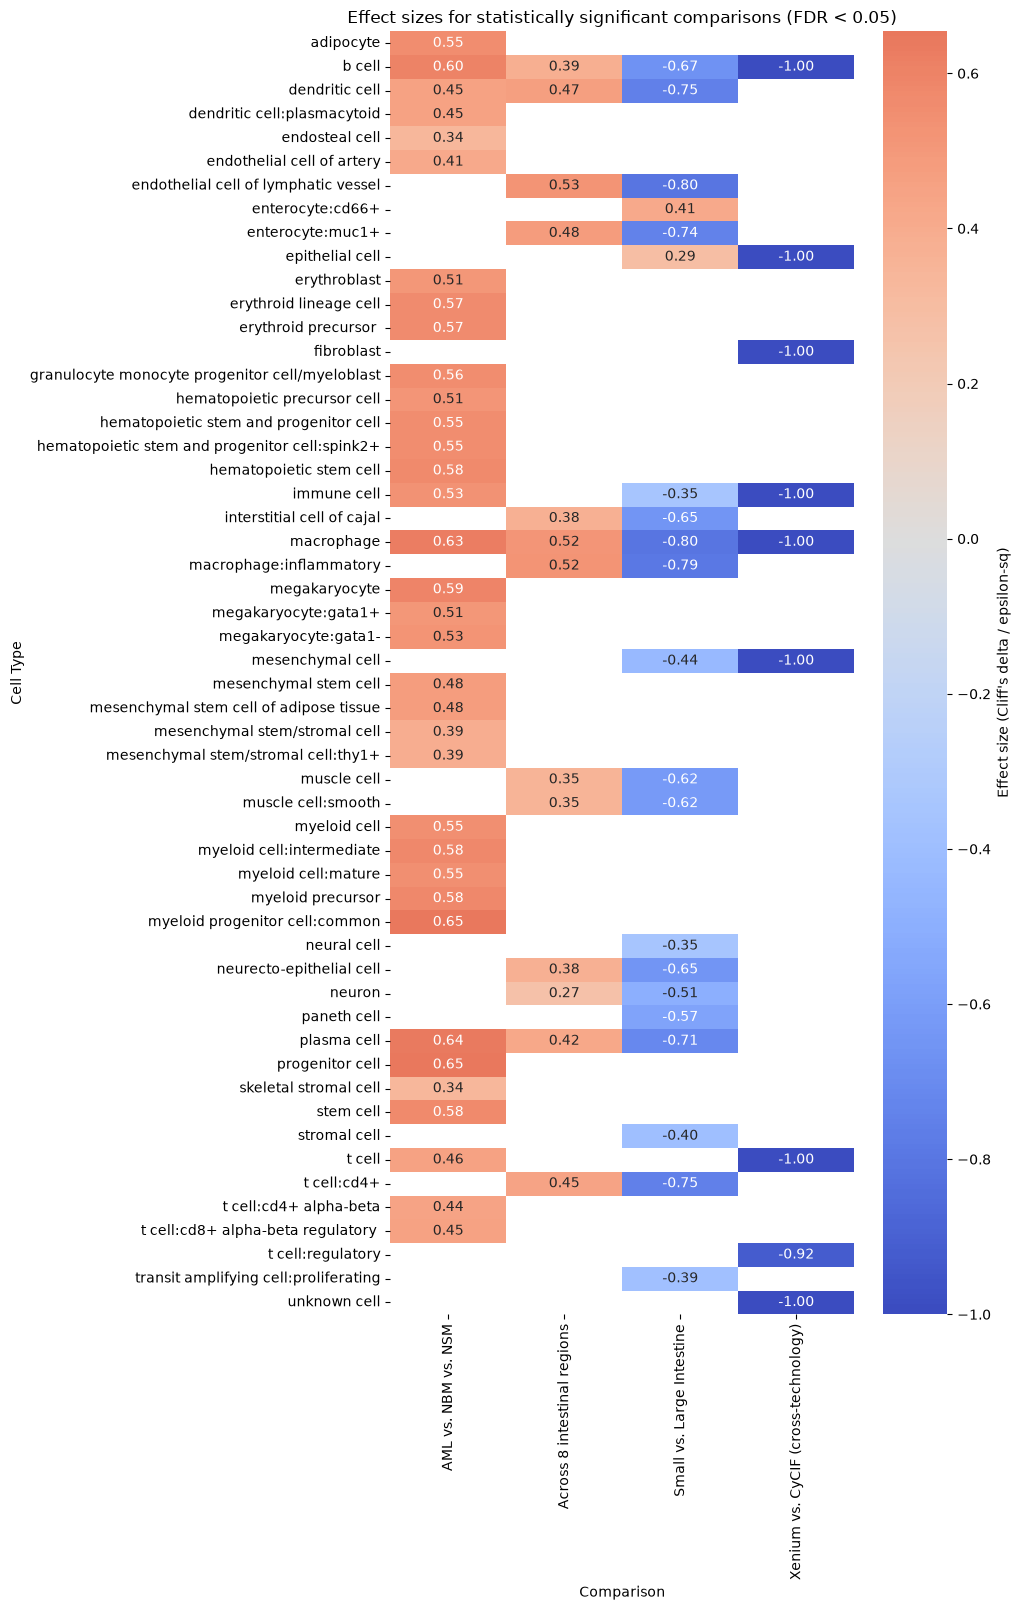

In [19]:
if len(significant) > 0:
    pivot = significant.pivot_table(
        values='Effect Size', index='Cell Type', columns='Comparison', aggfunc='first'
    )
    plt.figure(figsize=(10, max(4, 0.3 * len(pivot))))
    sns.heatmap(pivot, annot=True, fmt='.2f', cmap='coolwarm', center=0,
                cbar_kws={'label': 'Effect size (Cliff\'s delta / epsilon-sq)'})
    plt.title('Effect sizes for statistically significant comparisons (FDR < 0.05)')
    plt.tight_layout()
    plt.savefig('distance_analysis_effect_size_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("No comparisons currently in `significant`.")
